# CGSS 2023 描述性分析与研究选题探索

**课程用途：** 大数据分析与统计基础期中作业。原始数据来自本项目 `data/CGSS2023/CGSS2023.tab`，题项含义以同目录的问卷和变量对应表为准。本 Notebook 不导出逐人数据，所有图表均为探索性描述，不作因果推断或正式全国总体推断。

**运行顺序：** 从上到下执行所有单元。建议解释器 `/opt/anaconda3/envs/myenv/bin/python`。使用 `weight2` 展示加权比例，但没有抽样设计变量时不计算复杂抽样标准误。

## 1. 读取数据与字段字典

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import PercentFormatter
ROOT = Path.cwd()
if not (ROOT/'data/CGSS2023/CGSS2023.tab').exists(): ROOT = ROOT.parent
DATA = ROOT/'data/CGSS2023/CGSS2023.tab'
MAP = ROOT/'data/CGSS2023/CGSS2023问卷题号与数据库变量对应表.xlsx'
assert DATA.exists() and MAP.exists(), '请从项目根目录或 Notebook 所在目录运行，并确认 data/CGSS2023 文件齐全。'
df = pd.read_csv(DATA, sep='\t', dtype=str, low_memory=False)
codebook = pd.read_excel(MAP, sheet_name='CGSS2023编码表', header=1)
assert df.id.is_unique
print(f'样本数: {len(df):,}；原始字段数: {len(df.columns):,}；变量字典行数: {len(codebook):,}')
focus = ['id','dsource','weight2','isurban','a2','a3a','a7a','a8a','a15','a285','a33','a35','a36','a43e','a89b','a90b','b1','b2','b1810','c17q']
assert set(focus).issubset(df.columns)
display(codebook.loc[codebook['变量名'].isin(focus), ['变量名','调查方式','问卷题目','值标签']].set_index('变量名').loc[focus].head(20))

样本数: 11,326；原始字段数: 437；变量字典行数: 465


,调查方式,问卷题目,值标签
变量名,,,
id,入户调查/电话调查,无,NaN
dsource,入户调查/电话调查,无,1 入户面访\n2 电话调查
weight2,入户调查/电话调查,适用于完整数据,NaN
isurban,入户调查,无,-5 电话调查未调查\n1 居委会\n2 村委会
a2,入户调查/电话调查,性别【访问员记录】,1 男\n2 女
a3a,入户调查/电话调查,您的出生日期是什么？年,-5 电话调查未调查\n-3 拒绝回答\n-2 不知道
a7a,入户调查/电话调查,您目前的最高教育程度是：,-3 拒绝回答\n1 没有受过任何教育\n2 私塾、扫盲班\n3 小学\n4 初中\n5 职...
a8a,入户调查/电话调查,您个人去年（2022年）全年的总收入是多少？,9999996 收入高于百万位数\n9999997 不适用\n9999998 不知道\n99...
a15,入户调查/电话调查,您觉得您目前的身体健康状况是：,-3 拒绝回答\n-2 不知道\n1 很不健康\n2 比较不健康\n3 一般\n4 比较健康...


## 2. 清理约定与调查方式

**缺失码：** 对本 Notebook 使用的数值题，`-5`、`-4`、`-3`、`-2`、`-1` 统一排除；具体含义因题而异，须回到变量对应表核查。个人收入 `a8a` 的 `9999996` 表示超出记录位数，`9999997`–`9999999` 分别是不适用、不知道、拒答，均不作为实际收入。对随机模块题，原始空白多为未入该模块，不能直接解读为拒答。`dsource=1` 为入户、`2` 为电话；`weight2` 是完整数据的整合权重。

In [2]:
def num(col, valid=None, income=False):
    x = pd.to_numeric(df[col], errors='coerce').where(lambda s: s.ge(0))
    if income: x = x.where(x.lt(9_999_996))
    if valid is not None: x = x.where(x.isin(valid))
    return x
clean = pd.DataFrame(index=df.index)
clean['mode'] = num('dsource', [1,2]).map({1:'入户',2:'电话'})
clean['weight'] = pd.to_numeric(df.weight2, errors='coerce').where(lambda s:s.gt(0))
clean['age'] = (2023-num('a3a')).where(lambda s:s.between(18,100))
clean['female'] = num('a2',[1,2]).map({1:0,2:1})
clean['education'] = num('a7a',list(range(1,15)))
clean['income_2022'] = num('a8a',income=True)
clean['health'] = num('a15',[1,2,3,4,5])
clean['internet_frequency'] = num('a285',[1,2,3,4,5])
clean['trust'] = num('a33',[1,2,3,4,5])
clean['fairness'] = num('a35',[1,2,3,4,5])
clean['happiness'] = num('a36',[1,2,3,4,5])
clean['status'] = num('a43e',[1,2,3,4,5])
clean['father_education'] = num('a89b',list(range(1,15)))
clean['mother_education'] = num('a90b',list(range(1,15)))
clean['relative_status'] = num('b1',[1,2,3])
clean['mobility_3y'] = num('b2',[1,2,3])
clean['inequality_fair'] = num('b1810',[1,2,3])
clean['online_friend_trust'] = num('c17q',[1,2,3,4])
clean['urban'] = num('isurban',[1,2])
print(clean['mode'].value_counts().to_string())
print('有效整合权重:',clean.weight.notna().sum())

mode
电话    5743
入户    5583
有效整合权重: 11326


## 3. 字段覆盖率与结构性空白

In [3]:
vars_show=['age','female','education','income_2022','health','internet_frequency','trust','fairness','happiness','status','relative_status','mobility_3y','online_friend_trust']
coverage=pd.DataFrame({'valid_n':clean[vars_show].notna().sum()})
coverage['valid_pct']=100*coverage.valid_n/len(clean)
display(coverage.round(1))
module=pd.DataFrame({v:clean.groupby('mode')[v].apply(lambda s:s.notna().sum()) for v in ['fairness','internet_frequency','online_friend_trust','urban']})
display(module)
print('注意：约 7 千份的随机模块题不能以全体 11,326 人为分母。')

,valid_n,valid_pct
age,11242,99.3
female,11326,100.0
education,11325,100.0
income_2022,10621,93.8
health,11322,100.0
internet_frequency,6976,61.6
trust,11291,99.7
fairness,6989,61.7
happiness,11307,99.8
status,11221,99.1


,fairness,internet_frequency,online_friend_trust,urban
mode,,,,
入户,5554,5578,5583,5583
电话,1435,1398,0,0


注意：约 7 千份的随机模块题不能以全体 11,326 人为分母。


## 4. 样本分布与数值描述

In [4]:
num_cols=['age','income_2022','health','trust','fairness','happiness']
desc=clean[num_cols].describe(percentiles=[.25,.5,.75]).T.rename(columns={'count':'N','mean':'Mean','std':'SD','min':'Min','25%':'P25','50%':'P50','75%':'P75','max':'Max'})
display(desc.round(2))
print('教育程度编码分布（原始编码，详见变量字典）:')
display(clean.education.value_counts(dropna=False).sort_index().rename('n').to_frame())
print('收入的 99% 分位数与最大值（元）:',clean.income_2022.quantile(.99),clean.income_2022.max())

,N,Mean,SD,Min,P25,P50,P75,Max
age,11242.0,47.75,16.72,18.0,34.0,47.0,60.0,94.0
income_2022,10621.0,70178.74,205231.49,0.0,8500.0,40000.0,80000.0,9991300.0
health,11322.0,3.39,1.04,1.0,3.0,3.0,4.0,5.0
trust,11291.0,3.56,1.01,1.0,3.0,4.0,4.0,5.0
fairness,6989.0,3.30,1.01,1.0,3.0,4.0,4.0,5.0
happiness,11307.0,3.88,0.83,1.0,4.0,4.0,4.0,5.0


教育程度编码分布（原始编码，详见变量字典）:


,n
education,
1.0,625
2.0,28
3.0,1505
4.0,2506
5.0,199
6.0,1207
7.0,563
8.0,43
9.0,770


收入的 99% 分位数与最大值（元）: 500000.0 9991300.0


## 5. 关键指标：未加权与整合权重描述

二元化仅用于展示：自评健康 4–5 为较好、信任 4–5 为同意、社会公平 4–5 为公平、幸福 4–5 为幸福。随机模块题只使用**有该题有效回答者**作为分母。加权比例是整合权重下的描述，不报告设计型置信区间。

In [5]:
def rate(x, weight):
    ok=x.notna() & weight.notna()
    return pd.Series({'valid_n':int(ok.sum()),'unweighted_pct':100*x[ok].mean(),'weighted_pct':100*np.average(x[ok],weights=weight[ok])})
indicators={
 '自评健康较好':clean.health.ge(4).where(clean.health.notna()).astype(float),
 '同意多数人可信':clean.trust.ge(4).where(clean.trust.notna()).astype(float),
 '认为社会公平':clean.fairness.ge(4).where(clean.fairness.notna()).astype(float),
 '生活幸福':clean.happiness.ge(4).where(clean.happiness.notna()).astype(float),
 '互联网使用频繁':clean.internet_frequency.ge(4).where(clean.internet_frequency.notna()).astype(float),
}
rates=pd.DataFrame({k:rate(v,clean.weight) for k,v in indicators.items()}).T
display(rates.round(2))

,valid_n,unweighted_pct,weighted_pct
自评健康较好,11322.0,46.74,47.21
同意多数人可信,11291.0,65.13,65.71
认为社会公平,6989.0,51.25,52.06
生活幸福,11307.0,75.95,75.87
互联网使用频繁,6976.0,68.61,68.09


## 6. 图形：样本、收入与态度

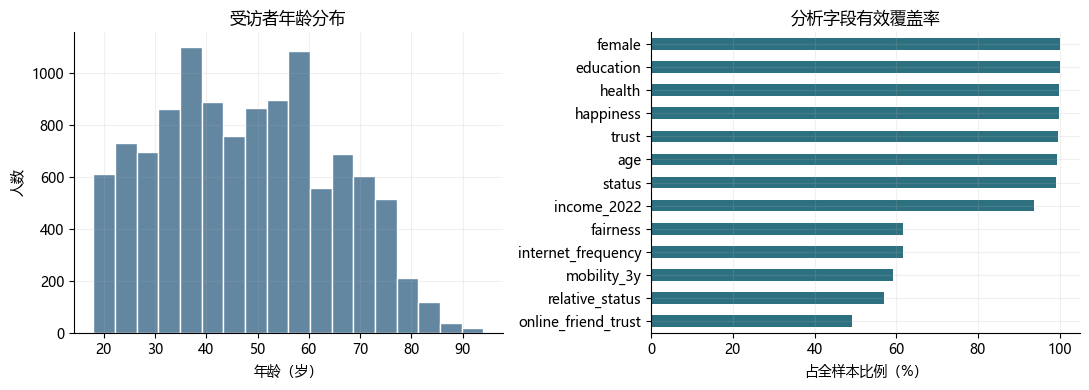

In [6]:
plt.rcParams.update({'font.family':'Microsoft YaHei','axes.unicode_minus':False,'figure.figsize':(7,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
fig,axs=plt.subplots(1,2,figsize=(11,4))
clean.age.dropna().plot.hist(bins=18,color='#6386A1',edgecolor='white',ax=axs[0])
axs[0].set(title='受访者年龄分布',xlabel='年龄（岁）',ylabel='人数')
coverage.valid_pct.sort_values().plot.barh(ax=axs[1],color='#2D7180')
axs[1].set(title='分析字段有效覆盖率',xlabel='占全样本比例（%）',ylabel='')
fig.tight_layout();plt.show()

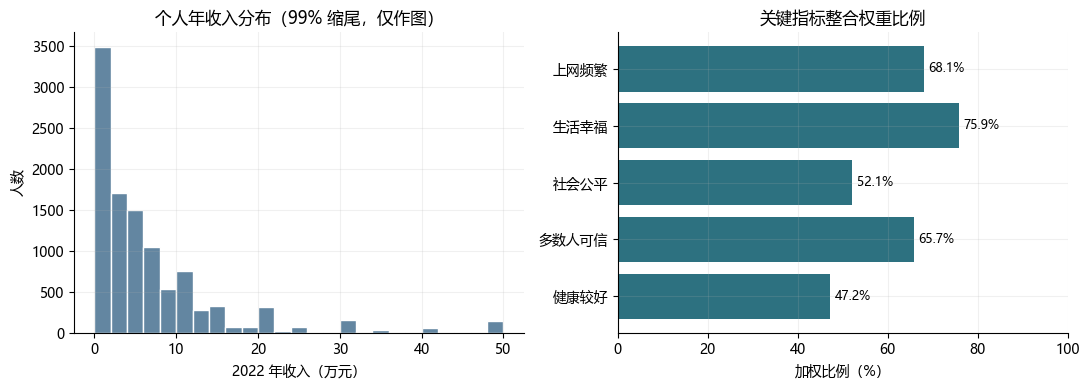

右图各题分母不同；公平感和互联网使用为随机模块题。


In [7]:
income=clean.income_2022.dropna(); cap=income.quantile(.99)
fig,axs=plt.subplots(1,2,figsize=(11,4))
income.clip(upper=cap).div(10000).plot.hist(bins=25,color='#6386A1',edgecolor='white',ax=axs[0])
axs[0].set(title='个人年收入分布（99% 缩尾，仅作图）',xlabel='2022 年收入（万元）',ylabel='人数')
labels=['健康较好','多数人可信','社会公平','生活幸福','上网频繁']
vals=rates.loc[['自评健康较好','同意多数人可信','认为社会公平','生活幸福','互联网使用频繁'],'weighted_pct']
axs[1].barh(labels,vals,color='#2D7180')
axs[1].set(title='关键指标整合权重比例',xlabel='加权比例（%）',xlim=(0,100))
for i,v in enumerate(vals):axs[1].text(v+1,i,f'{v:.1f}%',va='center',fontsize=9)
fig.tight_layout();plt.show()
print('右图各题分母不同；公平感和互联网使用为随机模块题。')

## 7. 候选关系的探索性分组

,n,fair_unweighted_pct,fair_weighted_pct
income_group,,,
Q1,1331.0,49.7,50.5
Q2,1330.0,56.1,55.4
Q3,1330.0,50.4,50.3
Q4,1330.0,51.8,53.7
Q5,1331.0,50.7,52.6


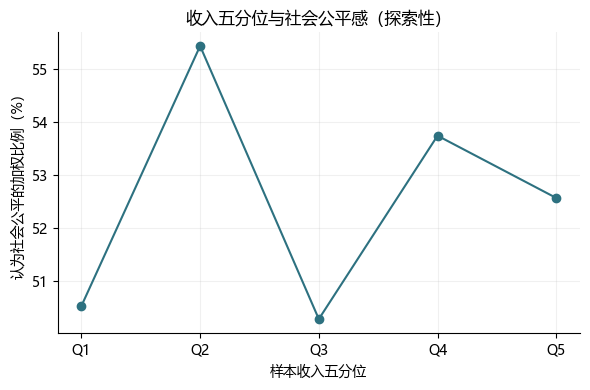

收入为 2022 年个人收入；五分位按此子样本分配，相同收入可能跨组。未控制混杂。


In [8]:
tmp=clean[['income_2022','fairness','weight']].dropna().copy()
tmp['income_group']=pd.qcut(tmp.income_2022.rank(method='first'),5,labels=['Q1','Q2','Q3','Q4','Q5'])
by_income=tmp.groupby('income_group',observed=True).apply(lambda g:pd.Series({'n':len(g),'fair_unweighted_pct':100*g.fairness.ge(4).mean(),'fair_weighted_pct':100*np.average(g.fairness.ge(4),weights=g.weight)}),include_groups=False)
display(by_income.round(1))
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(by_income.index.astype(str),by_income.fair_weighted_pct,marker='o',color='#2D7180')
ax.set(title='收入五分位与社会公平感（探索性）',xlabel='样本收入五分位',ylabel='认为社会公平的加权比例（%）')
fig.tight_layout();plt.show()
print('收入为 2022 年个人收入；五分位按此子样本分配，相同收入可能跨组。未控制混杂。')

In [9]:
tmp=clean[['internet_frequency','health','age','weight']].dropna().copy()
tmp['often_online']=tmp.internet_frequency.ge(4)
tmp['good_health']=tmp.health.ge(4)
by_digital=tmp.groupby('often_online').apply(lambda g:pd.Series({'n':len(g),'mean_age':g.age.mean(),'good_health_weighted_pct':100*np.average(g.good_health,weights=g.weight)}),include_groups=False)
display(by_digital.round(1))
print('上网频率与健康均为自报；年龄构成不同，不能推断上网影响健康。')

,n,mean_age,good_health_weighted_pct
often_online,,,
False,2189.0,64.2,33.0
True,4764.0,46.4,54.9


上网频率与健康均为自报；年龄构成不同，不能推断上网影响健康。


## 8. 可行性核查与选题入口

以下人数使用每题有效值的交集，未加模型条件和权重筛选。它们是**可分析规模**，并非最终回归样本。研究题目、创新点与设计建议见同目录 `选题建议.md`。

In [10]:
pairs={
 '数字使用与健康':['internet_frequency','health','age','education'],
 '收入位置与公平感':['income_2022','fairness','status','age'],
 '收入差距合理性与公平感':['inequality_fair','fairness','income_2022','status'],
 '三年社会流动与公平感':['mobility_3y','fairness','age','education'],
 '社会信任与幸福感':['trust','happiness','age','education'],
 '代际教育与数字使用':['father_education','mother_education','education','internet_frequency'],
 '网友信任与一般信任（入户）':['online_friend_trust','trust','age','education'],
}
feasible=pd.Series({k:int(clean[v].notna().all(axis=1).sum()) for k,v in pairs.items()},name='有效交集样本数').sort_values(ascending=False)
display(feasible.to_frame())
assert feasible.min()>3000
print('课程要求：原始数据 11,326 样本、437 字段；候选题最终样本仍需按模型变量重新计算。')

,有效交集样本数
社会信任与幸福感,11192
数字使用与健康,6953
收入位置与公平感,6582
代际教育与数字使用,6495
三年社会流动与公平感,5771
收入差距合理性与公平感,5624
网友信任与一般信任（入户）,5562


课程要求：原始数据 11,326 样本、437 字段；候选题最终样本仍需按模型变量重新计算。


## 9. 方法边界与下一步

- 2023 数据包含入户与电话调查；部分字段仅限入户或随机模块。建模时须控制或分层检查调查方式，切勿把 `-4/-5` 编码当成普通零值。
- `weight2` 适用于整合数据的描述。若研究只限入户，需回到编码表核查 `weight1`。缺少完整抽样设计信息时，不报告“全国代表性 95% 置信区间”。
- 对收入和公平感等横截面关联，不可直接写因果效应。先画出可能混杂因素和反向路径，再选择是否有可辩护的识别策略。
- 数据来源：CGSS 2023 本地 `.tab`、居民问卷与题号—变量对应表。出版或公开前请核对数据使用许可；本项目 `.gitignore` 排除 `data/`。